## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet', engine="pyarrow")
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

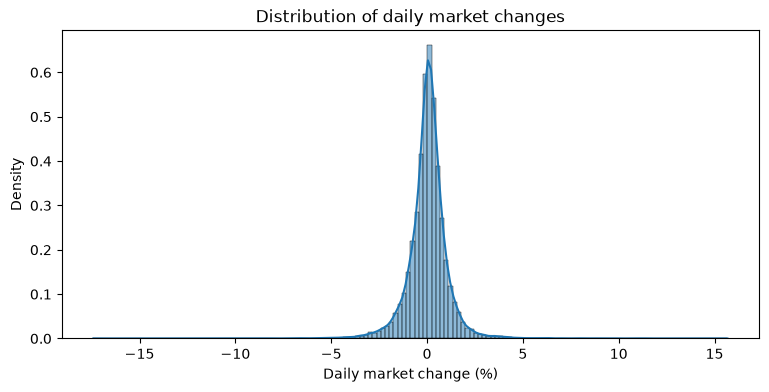

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

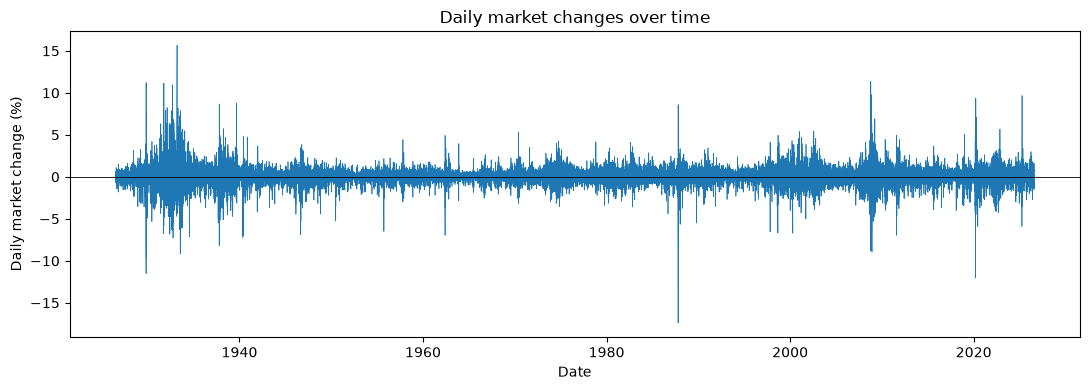

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [6]:
df['cat_today'] = np.where(df['market_return_pct'] > 0, 'Up', 'Down')

df['ret_today'] = df['market_return_pct']
df['ret_next'] = df['market_return_pct'].shift(-1)

df['cat_next'] = np.where(df['ret_next'] > 0, 'Up', 'Down')
df.loc[df['ret_next'].isna(), 'cat_next'] = np.nan

pairs = df.dropna(subset=['ret_next']).copy()

order = ['Up', 'Down']

joint = pd.crosstab(pairs['cat_today'], pairs['cat_next'], normalize='all')
joint = joint.reindex(index=order, columns=order)
joint.index.name = 'Today'
joint.columns.name = 'Next day'

marg_today = joint.sum(axis=1)
marg_next = joint.sum(axis=0)

cond = joint.div(marg_today, axis=0)

print("Joint PMF  P(today, next):")
print(joint.round(4), "\n")

print("Marginal PMF of today's category:")
print(marg_today.round(4), "\n")

print("Marginal PMF of next day's category:")
print(marg_next.round(4), "\n")

print("Conditional PMF  P(next | today):")
print(cond.round(4))

Joint PMF  P(today, next):
Next day      Up    Down
Today                   
Up        0.3190  0.2281
Down      0.2281  0.2247 

Marginal PMF of today's category:
Today
Up      0.5471
Down    0.4529
dtype: float64 

Marginal PMF of next day's category:
Next day
Up      0.5471
Down    0.4529
dtype: float64 

Conditional PMF  P(next | today):
Next day      Up    Down
Today                   
Up        0.5830  0.4170
Down      0.5038  0.4962


Yes, Up transitions are more likely.  Looking at the marginal PMF of the next day, it shows that .5471 are Up and .4529 are Down.

You're more likely to transition to an Up day from an Up day.  The conditional PMF shows that Up -> Up is .5830, while Down -> Up is .5038.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [7]:
bins   = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']

df['state_today'] = pd.cut(df['market_return_pct'], bins=bins, labels=labels, right=True)
df['ret_next']    = df['market_return_pct'].shift(-1)
df['state_next']  = df['state_today'].shift(-1)

counts = df['state_today'].value_counts().reindex(labels)
print("Days per state:")
print(pd.DataFrame({'days': counts, 'share': (counts / counts.sum()).round(4)}), "\n")
print("Most common:", counts.idxmax(), "| Least common:", counts.idxmin())

Days per state:
             days   share
state_today              
Large loss   2759  0.1049
Small loss   7452  0.2834
Near zero    3441  0.1309
Small gain   9785  0.3721
Large gain   2859  0.1087 

Most common: Small gain | Least common: Large loss


In [8]:
pairs = df.dropna(subset=['ret_next']).copy()

joint = pd.crosstab(pairs['state_today'], pairs['state_next'], normalize='all')
joint = joint.reindex(index=labels, columns=labels)
joint.index.name, joint.columns.name = 'Today', 'Next day'

marg_today = joint.sum(axis=1)
marg_next  = joint.sum(axis=0)

print("Joint PMF P(today, next):")
print(joint.round(4), "\n")
print("Marginal (today):\n", marg_today.round(4), "\n")
print("Marginal (next):\n", marg_next.round(4), "\n")

top_joint = joint.stack().sort_values(ascending=False)
print("Top 5 most likely transitions:")
print(top_joint.head(5).round(4))

Joint PMF P(today, next):
Next day    Large loss  Small loss  Near zero  Small gain  Large gain
Today                                                                
Large loss      0.0213      0.0272     0.0091      0.0278      0.0195
Small loss      0.0354      0.0886     0.0342      0.0978      0.0274
Near zero       0.0093      0.0420     0.0210      0.0493      0.0093
Small gain      0.0250      0.1001     0.0550      0.1594      0.0326
Large gain      0.0138      0.0255     0.0116      0.0378      0.0199 

Marginal (today):
 Today
Large loss    0.1049
Small loss    0.2834
Near zero     0.1309
Small gain    0.3721
Large gain    0.1087
dtype: float64 

Marginal (next):
 Next day
Large loss    0.1049
Small loss    0.2834
Near zero     0.1308
Small gain    0.3721
Large gain    0.1087
dtype: float64 

Top 5 most likely transitions:
Today       Next day  
Small gain  Small gain    0.1594
            Small loss    0.1001
Small loss  Small gain    0.0978
            Small loss    0.0886


Conditional PMF P(next | today):
Next day    Large loss  Small loss  Near zero  Small gain  Large gain
Today                                                                
Large loss      0.2033      0.2592     0.0863      0.2650      0.1863
Small loss      0.1251      0.3128     0.1205      0.3450      0.0966
Near zero       0.0712      0.3208     0.1601      0.3769      0.0709
Small gain      0.0672      0.2689     0.1479      0.4285      0.0876
Large gain      0.1273      0.2347     0.1070      0.3477      0.1833 

 Large loss: Small gain (0.265), Small loss (0.259)
 Small loss: Small gain (0.345), Small loss (0.313)
  Near zero: Small gain (0.377), Small loss (0.321)
 Small gain: Small gain (0.428), Small loss (0.269)
 Large gain: Small gain (0.348), Small loss (0.235)

Distance of each row from uniform:
            max |p - 0.2|  total variation dist.
Today                                           
Large loss         0.1137                 0.1274
Small loss         0.1450       

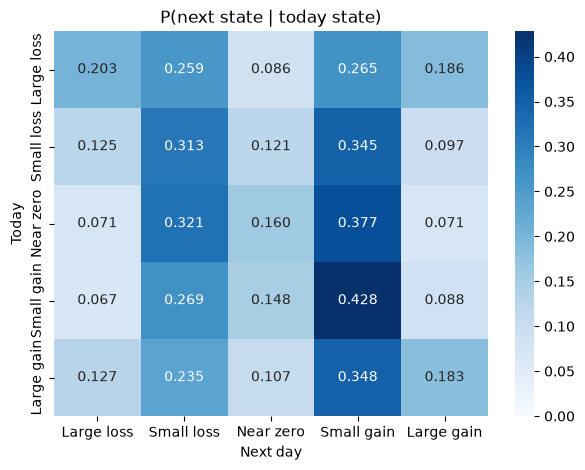

In [9]:
cond = joint.div(marg_today, axis=0)
print("Conditional PMF P(next | today):")
print(cond.round(4), "\n")

for state in labels:
    top2 = cond.loc[state].nlargest(2)
    print(f"{state:>11}: " + ", ".join(f"{s} ({p:.3f})" for s, p in top2.items()))

dev = pd.DataFrame({
    'max |p - 0.2|': (cond - 0.2).abs().max(axis=1),
    'total variation dist.': 0.5 * (cond - 0.2).abs().sum(axis=1),
})
print("\nDistance of each row from uniform:")
print(dev.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cond, annot=True, fmt='.3f', cmap='Blues', vmin=0, ax=ax)
ax.set(title='P(next state | today state)')
plt.show()

              count   mean    std    min   25%   50%   75%    max
state_today                                                      
Large loss   2759.0 -0.038  1.721 -17.41 -0.79 -0.01  0.72  11.22
Small loss   7452.0 -0.044  1.010 -11.23 -0.53  0.01  0.45  11.36
Near zero    3441.0  0.015  0.826  -8.19 -0.35  0.03  0.42   5.49
Small gain   9784.0  0.107  0.832  -8.25 -0.25  0.12  0.50   8.67
Large gain   2859.0  0.163  1.384 -12.00 -0.37  0.15  0.73  15.67

               mean    std    min    max  range
state_today                                   
Large loss  -0.038  1.721 -17.41  11.22  28.63
Small loss  -0.044  1.010 -11.23  11.36  22.59
Near zero    0.015  0.826  -8.19   5.49  13.68
Small gain   0.107  0.832  -8.25   8.67  16.92
Large gain   0.163  1.384 -12.00  15.67  27.67


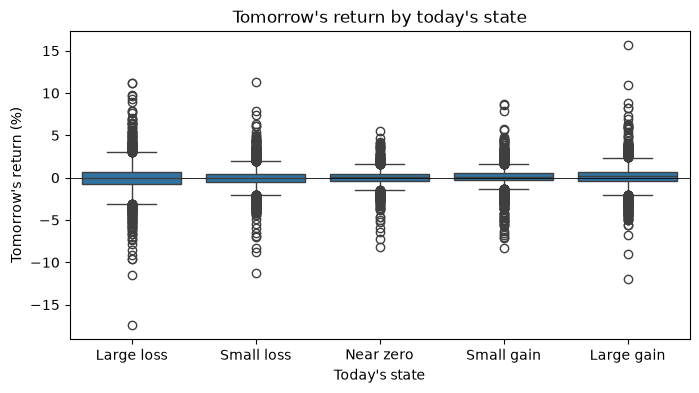

In [10]:
by_state = (pairs.groupby('state_today', observed=False)['ret_next']
                 .describe()
                 .reindex(labels))
print(by_state.round(3))

summary = by_state[['mean', 'std', 'min', 'max']].copy()
summary['range'] = summary['max'] - summary['min']
print("\n", summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=pairs, x='state_today', y='ret_next', order=labels, ax=ax)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel="Today's state", ylabel="Tomorrow's return (%)",
       title="Tomorrow's return by today's state")
plt.show()

I would say it's relatively difficult to predict the next state precisely, though it's easier to predict within a range.  The next day seems to nearly always be either a small loss or a small gain, so while the probabilities for a specific state would be difficult (they're generally sitting at .3 or lower, with a few exceptions), you can confidently say that the most likely outcomes are either small loss or small gain.


### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [11]:
df['y_t']   = pd.qcut(df['market_return_pct'], q=21, labels=False)
df['y_tp1'] = df['y_t'].shift(-1)

print(df['y_t'].value_counts().sort_index())

edges = pd.qcut(df['market_return_pct'], q=21, retbins=True)[1]
print("Bin edges:", np.round(edges, 3))

y_t
0     1255
1     1253
2     1286
3     1280
4     1230
5     1226
6     1371
7     1206
8     1198
9     1331
10    1210
11    1223
12    1294
13    1223
14    1310
15    1193
16    1211
17    1283
18    1225
19    1250
20    1238
Name: count, dtype: int64
Bin edges: [-17.41  -1.61  -1.07  -0.78  -0.57  -0.42  -0.3   -0.19  -0.11  -0.03
   0.04   0.11   0.18   0.26   0.34   0.44   0.54   0.67   0.84   1.09
   1.55  15.67]


In [12]:
pairs = df.dropna(subset=['y_tp1']).copy()
pairs['y_t']   = pairs['y_t'].astype(int)
pairs['y_tp1'] = pairs['y_tp1'].astype(int)

K = 21

joint = pd.crosstab(pairs['y_t'], pairs['y_tp1'], normalize='all')
joint = joint.reindex(index=range(K), columns=range(K), fill_value=0)
joint.index.name, joint.columns.name = 'Today (bin)', 'Next day (bin)'

print("Joint sums to 1:", np.isclose(joint.values.sum(), 1))
print(f"Uniform benchmark 1/21^2 = {1/K**2:.5f}")
print(f"Joint PMF range: {joint.values.min():.5f} to {joint.values.max():.5f}")

Joint sums to 1: True
Uniform benchmark 1/21^2 = 0.00227
Joint PMF range: 0.00072 to 0.00696


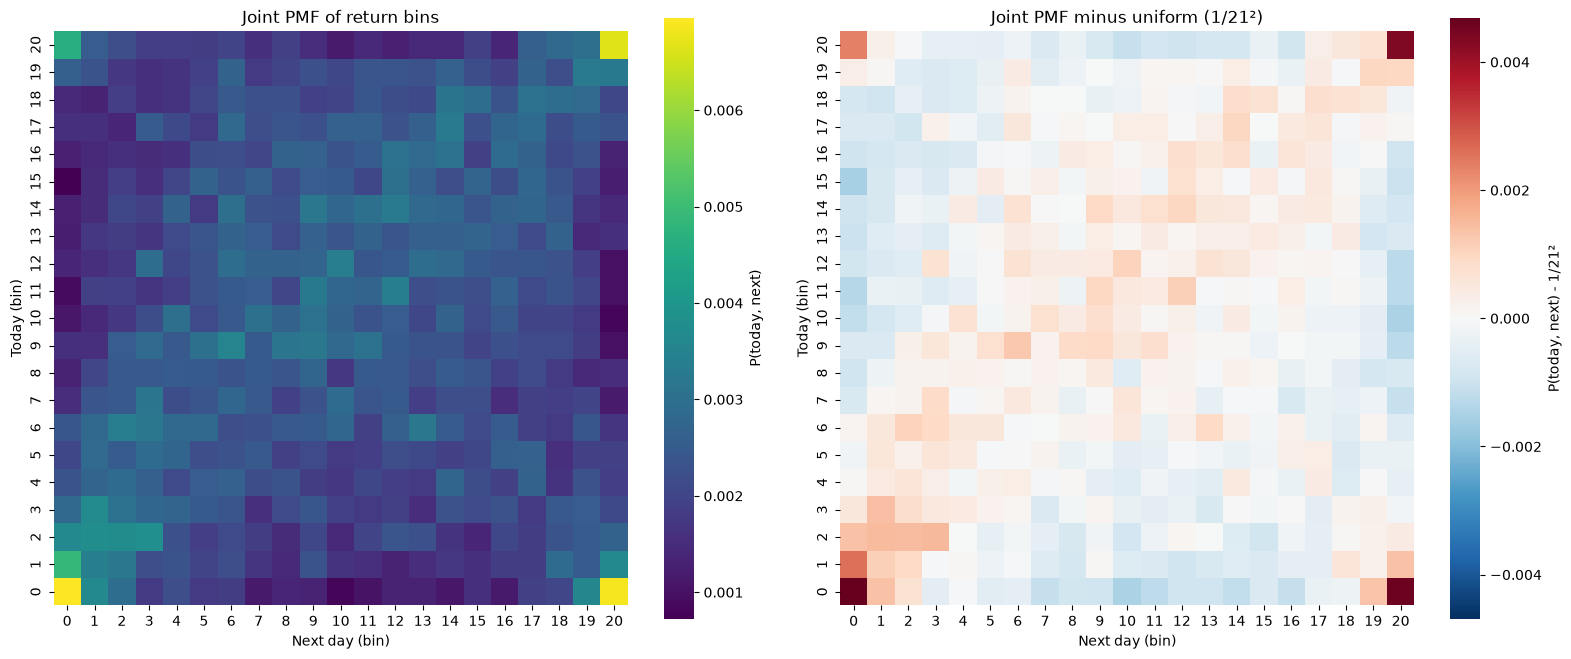

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

sns.heatmap(joint, cmap='viridis', square=True, ax=axes[0],
            cbar_kws={'label': 'P(today, next)'})
axes[0].set(title='Joint PMF of return bins')

dev = joint - 1/K**2
lim = np.abs(dev.values).max()
sns.heatmap(dev, cmap='RdBu_r', center=0, vmin=-lim, vmax=lim, square=True,
            ax=axes[1], cbar_kws={'label': 'P(today, next) - 1/21²'})
axes[1].set(title='Joint PMF minus uniform (1/21²)')

for ax in axes:
    ax.invert_yaxis()
fig.tight_layout()
plt.show()

There's definitely some sort of X shape in the heat map, with the lower left to upper right diagonal being more pronounced than the upper left to lower right diagonal.  That reflects the fact that the most common days are small losses and small gains.

In [14]:
marg_today = joint.sum(axis=1)
cond = joint.div(marg_today, axis=0)
cond.index.name, cond.columns.name = 'Today (bin)', 'Next day (bin)'

print("Each row sums to 1:", np.allclose(cond.sum(axis=1), 1))
print(f"Uniform benchmark 1/21 = {1/K:.5f}")
print(f"Conditional PMF range: {cond.values.min():.4f} to {cond.values.max():.4f}")

Each row sums to 1: True
Uniform benchmark 1/21 = 0.04762
Conditional PMF range: 0.0159 to 0.1458


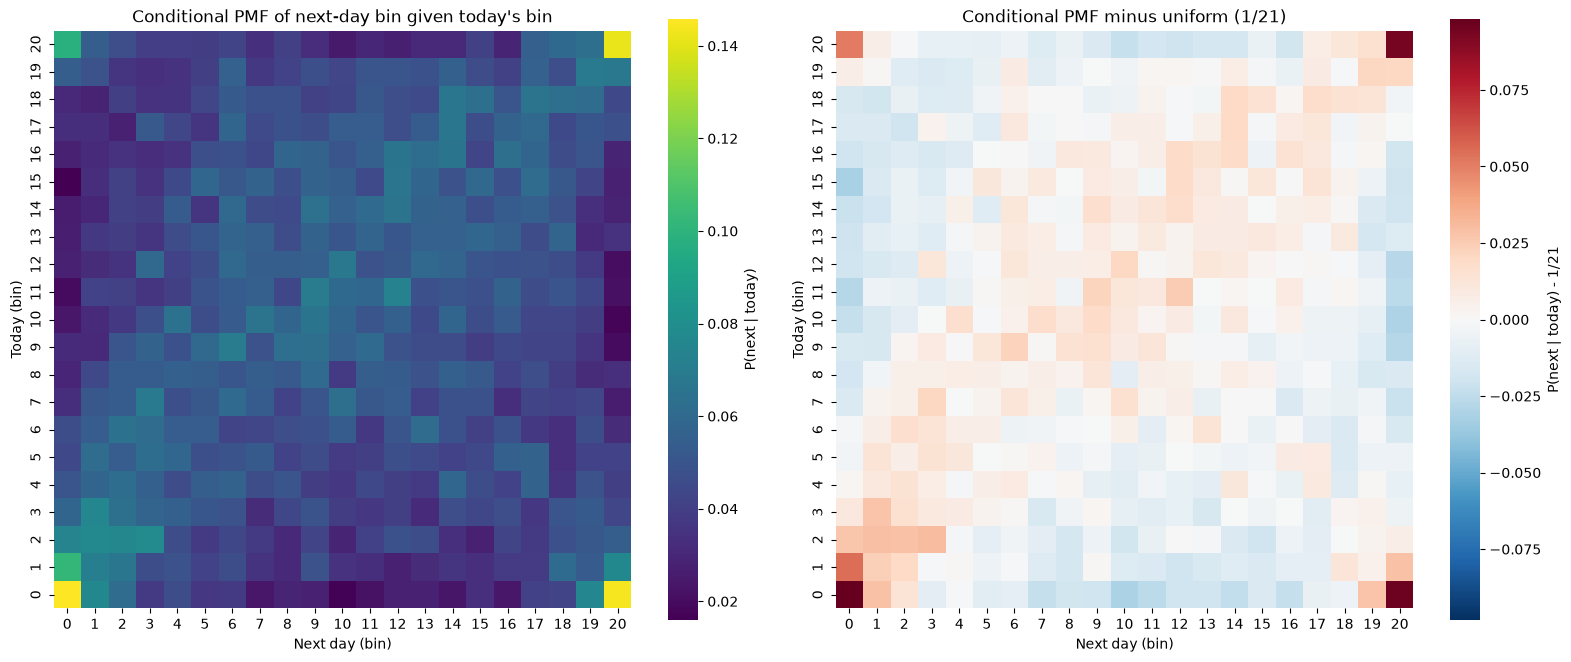

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

sns.heatmap(cond, cmap='viridis', square=True, ax=axes[0],
            cbar_kws={'label': 'P(next | today)'})
axes[0].set(title='Conditional PMF of next-day bin given today\'s bin')

dev_c = cond - 1/K
lim = np.abs(dev_c.values).max()
sns.heatmap(dev_c, cmap='RdBu_r', center=0, vmin=-lim, vmax=lim, square=True,
            ax=axes[1], cbar_kws={'label': 'P(next | today) - 1/21'})
axes[1].set(title='Conditional PMF minus uniform (1/21)')

for ax in axes:
    ax.invert_yaxis()
fig.tight_layout()
plt.show()

This is pretty much the exact same pattern as the joint PMF, which reflects that the most common next states (conditional on what the previous day was) are still small loss or small gain.

       min   mean    max
y_t                     
0   -17.41 -0.014  11.22
1    -7.36 -0.077   6.36
2    -8.79 -0.097  11.36
3    -8.28 -0.059   6.16
4    -6.89 -0.024   4.56
5   -11.23 -0.023   6.37
6    -3.94 -0.030   7.37
7    -3.40 -0.014   4.76
8    -6.00  0.026   5.49
9    -8.19 -0.013   3.60
10   -7.30  0.035   4.69
11   -8.25  0.092   7.88
12   -6.82  0.057   5.66
13   -5.12  0.088   4.16
14   -6.49  0.091   5.70
15   -6.99  0.126   8.67
16   -7.13  0.126   4.84
17   -6.30  0.130   8.60
18   -8.96  0.175   4.38
19   -4.93  0.133   6.04
20  -12.00  0.195  15.67


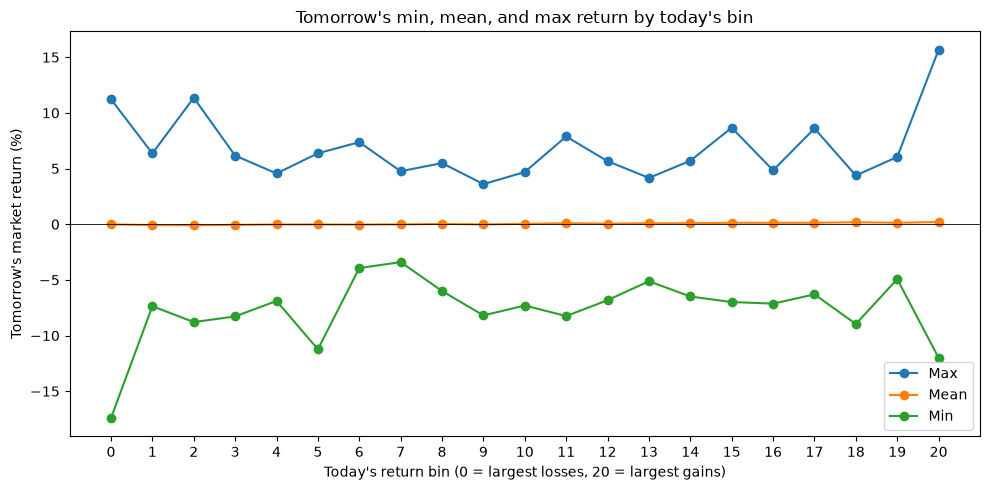

In [16]:
stats = (pairs.groupby('y_t')['ret_next']
              .agg(['min', 'mean', 'max'])
              .reindex(range(K)))
print(stats.round(3))

df['ret_next'] = df['market_return_pct'].shift(-1)
pairs = df.dropna(subset=['y_tp1']).copy()
pairs['y_t'] = pairs['y_t'].astype(int)
pairs['y_tp1'] = pairs['y_tp1'].astype(int)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(stats.index, stats['max'],  marker='o', label='Max')
ax.plot(stats.index, stats['mean'], marker='o', label='Mean')
ax.plot(stats.index, stats['min'],  marker='o', label='Min')
ax.axhline(0, color='black', linewidth=0.6)
ax.set_xticks(range(K))
ax.set(xlabel="Today's return bin (0 = largest losses, 20 = largest gains)",
       ylabel="Tomorrow's market return (%)",
       title="Tomorrow's min, mean, and max return by today's bin")
ax.legend()
fig.tight_layout()
plt.show()

From what I can see, the min and max seem to mirror each other, generally speaking.  There are some exceptions here, but it looks like larger maxes tend to mirror larger mins.  The main outlier is bin 5, which has a large min and relatively smaller max.

y_t
0     2.140
1     1.286
2     1.228
3     1.050
4     0.989
5     1.025
6     0.930
7     0.836
8     0.853
9     0.812
10    0.805
11    0.792
12    0.784
13    0.817
14    0.831
15    0.790
16    0.827
17    0.960
18    0.901
19    1.100
20    1.703
Name: ret_next, dtype: float64


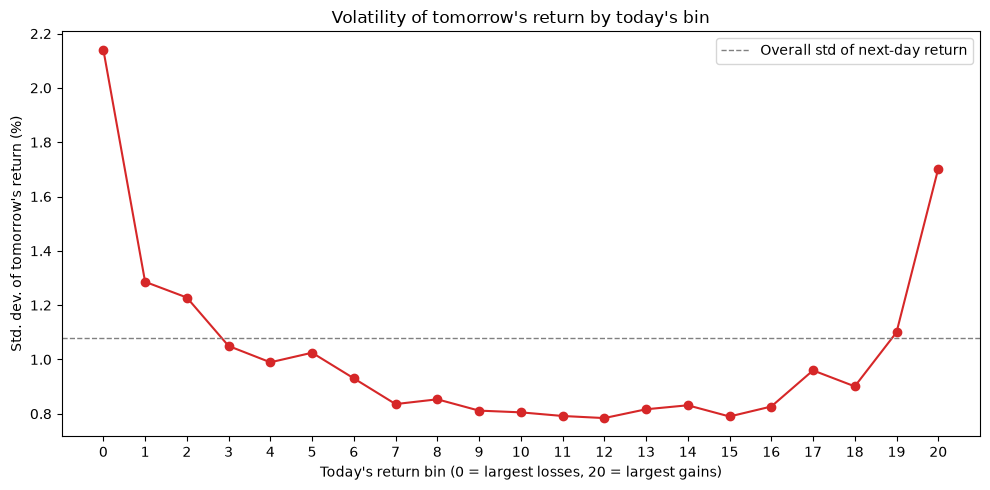

In [17]:
std_by_bin = (pairs.groupby('y_t')['ret_next']
                   .std()
                   .reindex(range(K)))
print(std_by_bin.round(3))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(std_by_bin.index, std_by_bin.values, marker='o', color='C3')
ax.axhline(pairs['ret_next'].std(), color='gray', linestyle='--', linewidth=1,
           label='Overall std of next-day return')
ax.set_xticks(range(K))
ax.set(xlabel="Today's return bin (0 = largest losses, 20 = largest gains)",
       ylabel="Std. dev. of tomorrow's return (%)",
       title="Volatility of tomorrow's return by today's bin")
ax.legend()
fig.tight_layout()
plt.show()

The standard deviation seems to be fairly consistent, though there are a few huge outliers.  The majority of the deviations are roughly .8 to ~1, but there are two particular deviations that approach or eclipse 2.

Overall, is the market easy to predict?  That honestly depends on what you're predicting.  It seems somewhat safe to predict either a small loss or small gain, so we generally know it's unlikely for there to be huge shifts in the market.  That being said, the odds of specifically predicting, say, a small gain aren't good, so that isn't easy to predict.  The market isn't incredibly volatile, but that doesn't mean it isn't easily predictable in my opinion.